# аттрактор Лоренца и горизонт предсказуемости

Рассматриваем систему

$$
\dot x=\sigma(y-x),\qquad
\dot y=x(\rho-z)-y,\qquad
\dot z=xy-\beta z,
$$

где $\sigma=10$, $\beta=8/3$, начальное состояние $(1,1,1)$.
Сравниваем $\rho=10$ и $\rho=28$. Время и координаты безразмерные.
Интегрируем методом DOP853 через `solve_ivp`.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

sigma = 10.0
beta = 8 / 3
start = np.array([1.0, 1.0, 1.0])
rhos = [10, 28]

settings = dict(rtol=1e-9, atol=1e-12, max_step=0.05)
fine_settings = dict(rtol=1e-12, atol=1e-14, max_step=0.01)
check_settings = dict(rtol=1e-13, atol=1e-15, max_step=0.005)


In [3]:
def rhs(t, state, rho):  # правая часть для одной траектории или нескольких независимых траекторий
    x, y, z = state.reshape(-1, 3).T
    return np.column_stack((sigma * (y - x), x * (rho - z) - y, x * y - beta * z)).ravel()


def integrate(initial, rho, duration, options, **kwargs):  # решение с заданными допусками и ограничением шага
    solution = solve_ivp(rhs, (0, duration), np.asarray(initial).ravel(),
                         args=(rho,), method='DOP853', **options, **kwargs)
    if not solution.success:
        raise RuntimeError(solution.message)
    return solution


## временные ряды и фазовый портрет

Первоначальный расчёт ведём до $t=80$. Для дальнейших опытов выбираем состояние при $t=50$, после переходного процесса.
На временных рядах показан участок $0\leq t\leq60$, на фазовом портрете при $\rho=28$ — участок $50\leq t\leq80$.


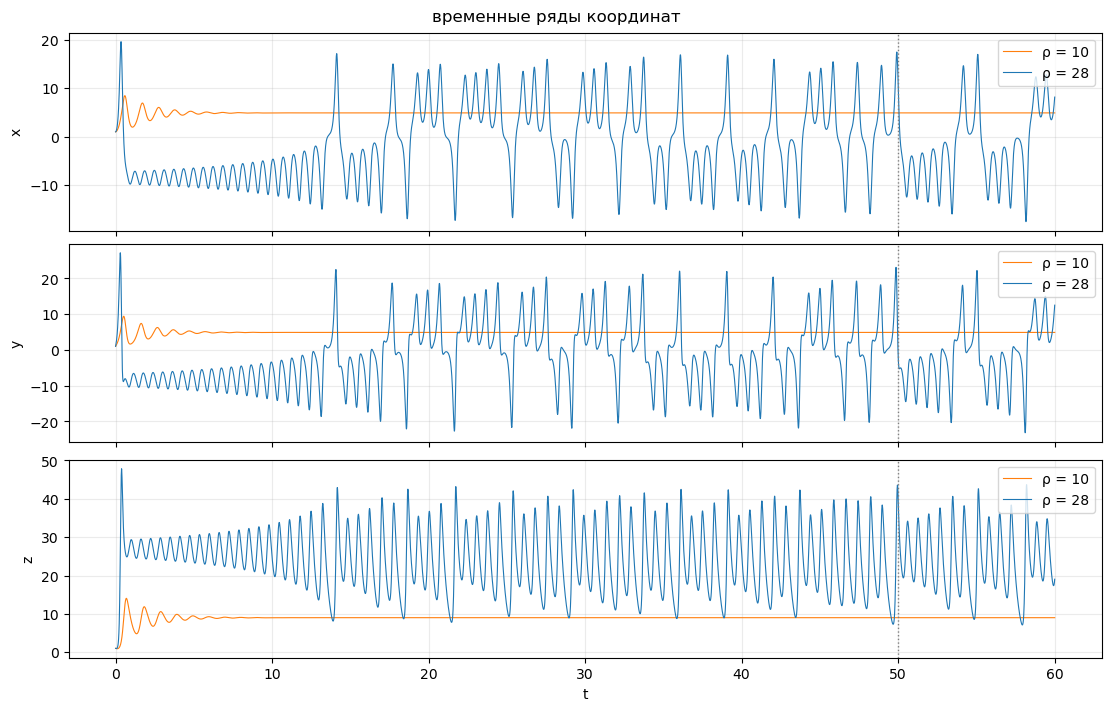

In [4]:
orbits = {rho: integrate(start, rho, 80, fine_settings, dense_output=True) for rho in rhos}
attractor_starts = {rho: orbits[rho].sol(50) for rho in rhos}
t_view = np.linspace(0, 60, 6001)
t_phase = np.linspace(50, 80, 6001)
phase = orbits[28].sol(t_phase).T

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
for rho, color in [(10, 'tab:orange'), (28, 'tab:blue')]:
    values = orbits[rho].sol(t_view)
    for j, ax in enumerate(axes):
        ax.plot(t_view, values[j], color=color, linewidth=0.8, label=f'ρ = {rho}')
for ax, name in zip(axes, ['x', 'y', 'z']):
    ax.axvline(50, color='gray', linestyle=':', linewidth=1)
    ax.set_ylabel(name)
    ax.grid(alpha=0.25)
    ax.legend(loc='upper right')
axes[-1].set_xlabel('t')
fig.suptitle('временные ряды координат')
plt.show()


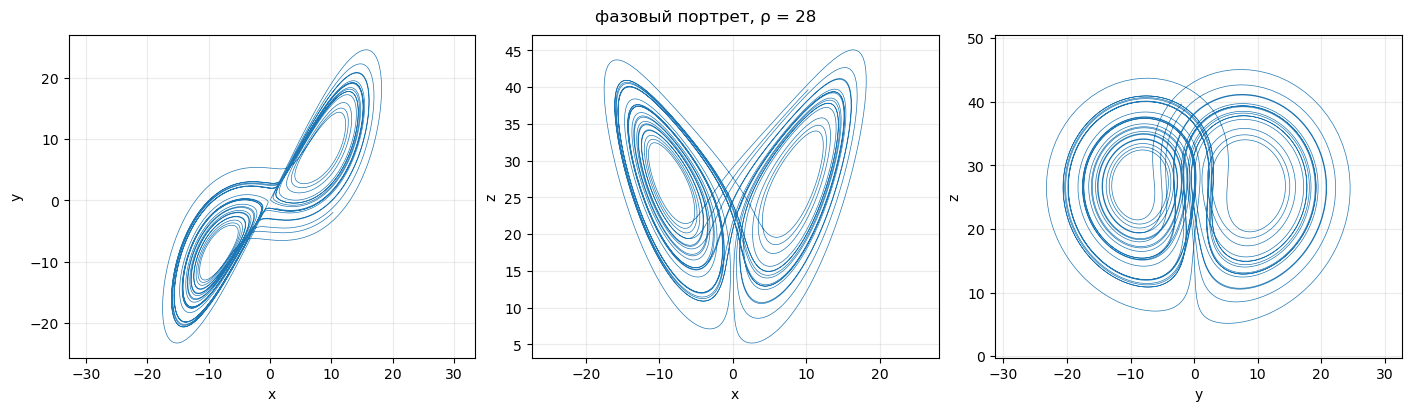

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, (i, j), labels in zip(axes, [(0, 1), (0, 2), (1, 2)], [('x', 'y'), ('x', 'z'), ('y', 'z')]):
    ax.plot(phase[:, i], phase[:, j], color='tab:blue', linewidth=0.5)
    ax.set(xlabel=labels[0], ylabel=labels[1])
    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(alpha=0.25)
fig.suptitle('фазовый портрет, ρ = 28')
plt.show()


## расхождение близких траекторий

Из одной и той же точки при $t=50$ запускаем два решения с разностью $\delta_0=10^{-6}$ по координате $x$.
Здесь и далее новое время отсчитываем от момента запуска пары.
Расстояние между состояниями:

$$
d(t)=\sqrt{(x_2-x_1)^2+(y_2-y_1)^2+(z_2-z_1)^2}.
$$

Повторяем расчёт с более строгими допусками и меньшим максимальным шагом.
Изменение результата при уточнении оцениваем отдельно для каждого из двух одинаковых начальных состояний и берём большее из двух расстояний.
Шаг вывода на график — 0.01; внутренние шаги интегратора адаптивные.


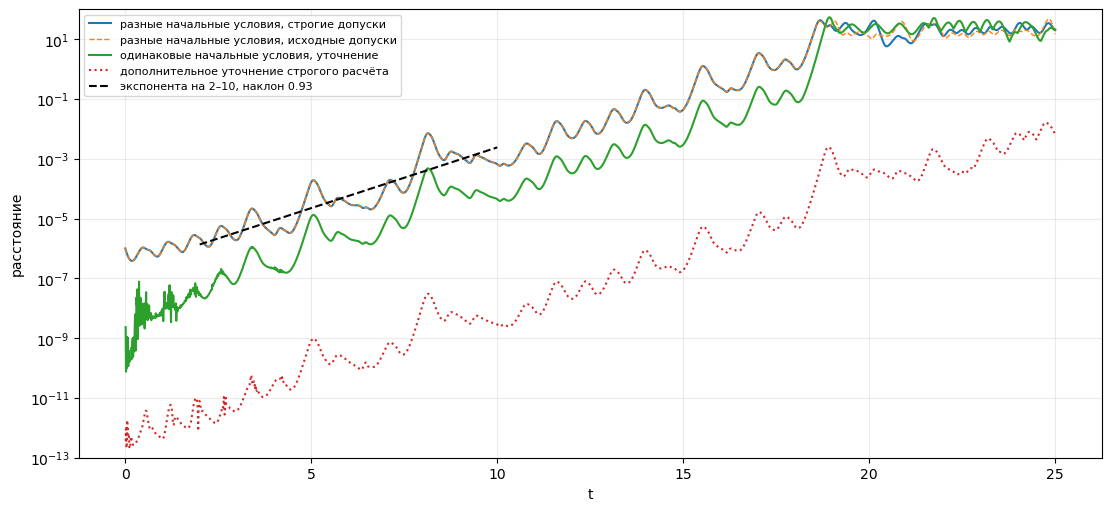

Наклон ln d(t) на участке 2–10: 0.9349
Изменение строгого решения при уточнении до t = 20: 2.479e-03


In [6]:
delta_0 = 1e-6
pair_start = np.r_[attractor_starts[28], attractor_starts[28] + [delta_0, 0, 0]]
t_pair = np.linspace(0, 25, 2501)
pair_solutions = []
for options in [settings, fine_settings, check_settings]:
    sol = integrate(pair_start, 28, 25, options, t_eval=t_pair)
    pair_solutions.append(sol.y.T.reshape(-1, 2, 3))
pair, pair_fine, pair_check = pair_solutions

distance = np.linalg.norm(pair[:, 1] - pair[:, 0], axis=1)
distance_fine = np.linalg.norm(pair_fine[:, 1] - pair_fine[:, 0], axis=1)
numerical_difference = np.max(np.linalg.norm(pair - pair_fine, axis=2), axis=1)
fine_difference = np.max(np.linalg.norm(pair_fine - pair_check, axis=2), axis=1)

fit_mask = (t_pair >= 2) & (t_pair <= 10)
fit_rate, fit_intercept = np.polyfit(t_pair[fit_mask], np.log(distance_fine[fit_mask]), 1)

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
ax.semilogy(t_pair, distance_fine, color='tab:blue', label='разные начальные условия, строгие допуски')
ax.semilogy(t_pair, distance, '--', color='tab:orange', linewidth=1,
            label='разные начальные условия, исходные допуски')
ax.semilogy(t_pair[1:], numerical_difference[1:], color='tab:green',
            label='одинаковые начальные условия, уточнение')
ax.semilogy(t_pair[1:], fine_difference[1:], ':', color='tab:red',
            label='дополнительное уточнение строгого расчёта')
ax.semilogy(t_pair[fit_mask], np.exp(fit_intercept + fit_rate * t_pair[fit_mask]),
            '--', color='black', label=f'экспонента на 2–10, наклон {fit_rate:.2f}')
ax.set(xlabel='t', ylabel='расстояние', ylim=(1e-13, 1e2))
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
plt.show()
print(f'Наклон ln d(t) на участке 2–10: {fit_rate:.4f}')
print(f'Изменение строгого решения при уточнении до t = 20: {fine_difference[t_pair <= 20].max():.3e}')


На участке $2\leq t\leq10$ средний рост близок к экспоненциальному, хотя расстояние сильно колеблется.
Наклон на этом коротком участке не обязан совпадать со старшим показателем Ляпунова.
При больших расстояниях линейное приближение перестаёт работать: обе траектории остаются в ограниченной области аттрактора, поэтому бесконечного роста нет. Расстояние после насыщения продолжает меняться.


## старший показатель Ляпунова

Через каждый интервал $\tau$ измеряем расстояние $d_k$ между двумя решениями и возвращаем его к $\delta$, сохраняя направление возмущения:

$$
v_k\longleftarrow u_k+\delta\frac{v_k-u_k}{\|v_k-u_k\|}.
$$

Здесь $u_k$ — основная траектория, $v_k$ — возмущённая. Перенормируем только вторую траекторию.
Накопленная оценка:

$$
\lambda_{\max}(T)=\frac{1}{T}\sum_{k=1}^{N}\ln\frac{d_k}{\delta},\qquad T=N\tau.
$$

После переходного процесса первые 20 единиц времени с перенормировкой не включаем в среднее: за это время направление возмущения перестраивается.
Основной расчёт: $\delta=10^{-6}$, $\tau=0.5$, время усреднения $T=1000$.


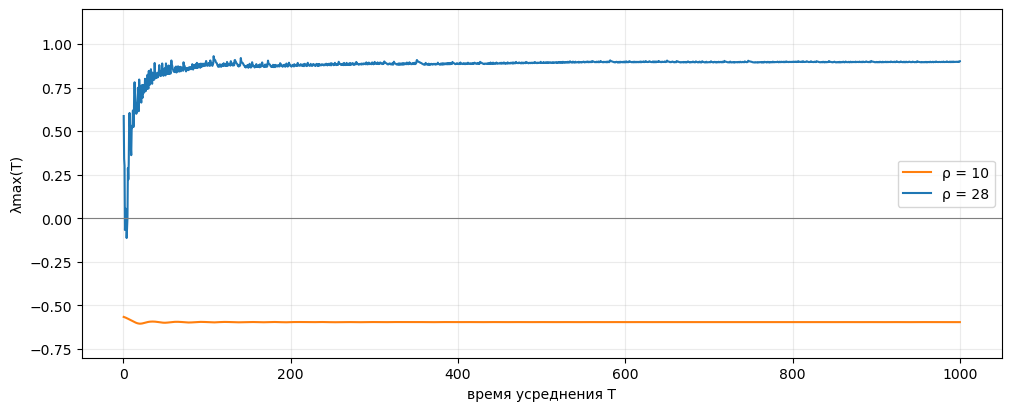

In [7]:
def lyapunov(initial, rho, duration=1000, delta=1e-6, interval=0.5,
             options=settings, alignment=20):  # две траектории с перенормировкой и накоплением логарифмов роста
    u = np.asarray(initial).copy()
    v = u + np.array([delta, 0, 0])
    n_skip = round(alignment / interval)
    n = round(duration / interval)
    growth = np.empty(n)
    for k in range(n_skip + n):
        sol = integrate(np.r_[u, v], rho, interval, options)
        u, v = sol.y[:, -1].reshape(2, 3)
        difference = v - u
        distance = np.linalg.norm(difference)
        if not np.isfinite(distance) or distance == 0:
            raise RuntimeError('не удалось разрешить расстояние между траекториями')
        if k >= n_skip:
            growth[k - n_skip] = np.log(distance / delta)
        v = u + delta * difference / distance
    time = interval * np.arange(1, n + 1)
    return time, np.cumsum(growth) / time, growth


lyapunov_results = {rho: lyapunov(attractor_starts[rho], rho) for rho in rhos}
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for rho, color in [(10, 'tab:orange'), (28, 'tab:blue')]:
    time, estimate, _ = lyapunov_results[rho]
    ax.plot(time, estimate, color=color, label=f'ρ = {rho}')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set(xlabel='время усреднения T', ylabel='λmax(T)', ylim=(-0.8, 1.2))
ax.grid(alpha=0.25)
ax.legend()
plt.show()


In [8]:
print(f"{'ρ':>5} {'T':>8} {'λmax(T)':>13}")
for rho in rhos:
    time, estimate, _ = lyapunov_results[rho]
    for duration in [100, 250, 500, 1000]:
        index = np.searchsorted(time, duration)
        print(f'{rho:5} {duration:8} {estimate[index]:13.6f}')

# Для устойчивого равновесия сравниваем оценку с собственными значениями матрицы линеаризации.
x_eq = np.sqrt(beta * (10 - 1))
jacobian = np.array([[-sigma, sigma, 0], [1, -1, -x_eq], [x_eq, x_eq, -beta]])
lambda_equilibrium = np.max(np.linalg.eigvals(jacobian).real)
print(f'\nСтаршая действительная часть собственных значений при ρ = 10: {lambda_equilibrium:.6f}')


    ρ        T       λmax(T)
   10      100     -0.595549
   10      250     -0.596195
   10      500     -0.595337
   10     1000     -0.595681
   28      100      0.878166
   28      250      0.886472
   28      500      0.892920
   28     1000      0.902123

Старшая действительная часть собственных значений при ρ = 10: -0.595497


## проверка устойчивости оценки

Для сравнения настроек время усреднения одинаковое: $T=500$.
Меняем по одному параметру: $\delta$, $\tau$ или точность интегрирования.
Все расчёты начинаются из тех же выбранных точек, начальное направление возмущения — вдоль $x$.


In [9]:
configurations = [
    ('исходные', 1e-6, 0.5, settings),
    ('δ = 1e-8', 1e-8, 0.5, settings),
    ('δ = 1e-4', 1e-4, 0.5, settings),
    ('τ = 0.25', 1e-6, 0.25, settings),
    ('τ = 1', 1e-6, 1.0, settings),
    ('мягче', 1e-6, 0.5, dict(rtol=1e-7, atol=1e-10, max_step=0.1)),
    ('строже', 1e-6, 0.5, dict(rtol=1e-11, atol=1e-14, max_step=0.025)),
]
stability_results = []
print(f"{'изменение':>12} {'δ':>9} {'τ':>6} {'rtol':>9} {'atol':>9} {'max_step':>10} {'λ, ρ=10':>11} {'λ, ρ=28':>11}")
for name, delta, interval, options in configurations:
    values = []
    for rho in rhos:
        if name == 'исходные':
            time, estimate, _ = lyapunov_results[rho]
            value = estimate[np.searchsorted(time, 500)]
        else:
            _, estimate, _ = lyapunov(attractor_starts[rho], rho, duration=500,
                                      delta=delta, interval=interval, options=options)
            value = estimate[-1]
        values.append(value)
    stability_results.append(values)
    print(f"{name:>12} {delta:9.0e} {interval:6.2f} {options['rtol']:9.0e} {options['atol']:9.0e} "
          f"{options['max_step']:10.3f} {values[0]:11.6f} {values[1]:11.6f}")
stability_results = np.array(stability_results)

print('\nОценки по десяти последовательным блокам длины 100 в основном расчёте:')
for rho in rhos:
    _, _, growth = lyapunov_results[rho]
    block_estimates = growth.reshape(10, -1).sum(axis=1) / 100
    print(f'ρ = {rho}: от {block_estimates.min():.4f} до {block_estimates.max():.4f}')


   изменение         δ      τ      rtol      atol   max_step     λ, ρ=10     λ, ρ=28
    исходные     1e-06   0.50     1e-09     1e-12      0.050   -0.595337    0.892920
    δ = 1e-8     1e-08   0.50     1e-09     1e-12      0.050   -0.595337    0.891062
    δ = 1e-4     1e-04   0.50     1e-09     1e-12      0.050   -0.595337    0.900902
    τ = 0.25     1e-06   0.25     1e-09     1e-12      0.050   -0.595337    0.898845
       τ = 1     1e-06   1.00     1e-09     1e-12      0.050   -0.595337    0.877056
       мягче     1e-06   0.50     1e-07     1e-10      0.100   -0.595337    0.909220
      строже     1e-06   0.50     1e-11     1e-14      0.025   -0.595337    0.901197

Оценки по десяти последовательным блокам длины 100 в основном расчёте:
ρ = 10: от -0.5984 до -0.5926
ρ = 28: от 0.8756 до 0.9509


При $\rho=10$ траектория стремится к устойчивому равновесию, поэтому старший показатель отрицателен.
При $\rho=28$ он положителен. Изменение настроек сохраняет знак и близкую величину оценки.
В хаотическом режиме оценки за конечное время немного различаются: изменяется сама длинная траектория и доля времени, проведённая в разных частях аттрактора. Разброс по блокам показывает масштаб этих колебаний.


## горизонт предсказуемости

Выбираем допустимое расстояние $\Delta=0.1$, малое по сравнению с размером аттрактора.
При экспоненциальном росте

$$
T_{\mathrm{pred}}\approx\frac{\ln(\Delta/\delta_0)}{\lambda_{\max}}.
$$

Берём шесть точек исходной траектории при $t=50,52,\ldots,60$ и возмущаем каждую вдоль $x$.
Для пяти значений $\delta_0$ находим первое достижение $d(t)=\Delta$ с помощью события интегратора.
В этих расчётах перенормировки нет. Каждую пару повторяем с более строгими настройками.


In [10]:
def crossing_time(initial, delta, threshold, options, duration=40):  # первое достижение допустимого расстояния
    pair = np.r_[initial, initial + np.array([delta, 0, 0])]

    def crossing(t, state, rho):  # событие при росте расстояния через порог
        return np.linalg.norm(state[3:] - state[:3]) - threshold

    crossing.terminal = True
    crossing.direction = 1
    solution = integrate(pair, 28, duration, options, events=crossing)
    return solution.t_events[0][0] if len(solution.t_events[0]) else np.nan


threshold = 0.1
deltas = 10.0**np.arange(-4, -9, -1)
seed_times = np.arange(50, 61, 2)
seeds = orbits[28].sol(seed_times).T
hit_times = np.empty((len(seeds), len(deltas)))
hit_times_check = np.empty_like(hit_times)
for i, initial in enumerate(seeds):
    for j, delta in enumerate(deltas):
        hit_times[i, j] = crossing_time(initial, delta, threshold, fine_settings)
        hit_times_check[i, j] = crossing_time(initial, delta, threshold, check_settings)

if not np.isfinite(hit_times).all() or not np.isfinite(hit_times_check).all():
    raise RuntimeError('не все пары достигли порога до t = 40')

lambda_max = lyapunov_results[28][1][-1]
theory = np.log(threshold / deltas) / lambda_max
median_times = np.median(hit_times, axis=0)
attractor_scale = np.linalg.norm(np.ptp(phase, axis=0))
print(f'Диагональ области, охватывающей фазовую траекторию: {attractor_scale:.2f}')
print(f'Порог Δ = {threshold}; доля от этого масштаба: {threshold / attractor_scale:.3e}')
print(f'Максимальное изменение времени достижения при уточнении: {np.max(np.abs(hit_times - hit_times_check)):.3e}')


Диагональ области, охватывающей фазовую траекторию: 71.73
Порог Δ = 0.1; доля от этого масштаба: 1.394e-03
Максимальное изменение времени достижения при уточнении: 1.383e-04


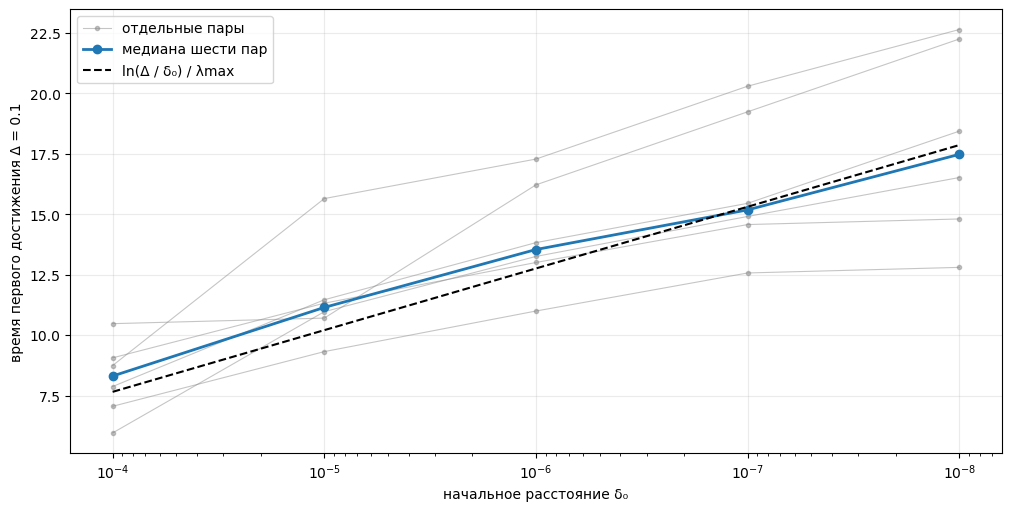

        δ₀     минимум     медиана    максимум      теория
     1e-04       5.957       8.311      10.478       7.657
     1e-05       9.322      11.149      15.653      10.210
     1e-06      11.001      13.545      17.287      12.762
     1e-07      12.575      15.185      20.302      15.314
     1e-08      12.806      17.483      22.647      17.867


In [11]:
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
for i, times in enumerate(hit_times):
    ax.plot(deltas, times, 'o-', color='gray', alpha=0.45, linewidth=0.8,
             markersize=3, label='отдельные пары' if i == 0 else None)
ax.plot(deltas, median_times, 'o-', color='tab:blue', linewidth=2, label='медиана шести пар')
ax.plot(deltas, theory, '--', color='black', label='ln(Δ / δ₀) / λmax')
ax.set_xscale('log')
ax.invert_xaxis()
ax.set(xlabel='начальное расстояние δ₀', ylabel='время первого достижения Δ = 0.1')
ax.grid(alpha=0.25)
ax.legend()
plt.show()

print(f"{'δ₀':>10} {'минимум':>11} {'медиана':>11} {'максимум':>11} {'теория':>11}")
for j, delta in enumerate(deltas):
    print(f'{delta:10.0e} {hit_times[:, j].min():11.3f} {median_times[j]:11.3f} '
          f'{hit_times[:, j].max():11.3f} {theory[j]:11.3f}')


Если начальное расстояние уменьшить в десять раз, теоретическая прибавка времени равна

$$
T_{\mathrm{pred}}(\delta_0/10)-T_{\mathrm{pred}}(\delta_0)
=\frac{\ln 10}{\lambda_{\max}}.
$$

Горизонт растёт на фиксированную добавку, а не в десять раз.
У отдельных пар добавка меняется: локальная скорость расхождения и направление возмущения зависят от точки на аттракторе. Поэтому формула даёт характерный масштаб времени, а не точное время первого достижения для каждой пары.


In [12]:
predicted_gain = np.log(10) / lambda_max
observed_gains = np.diff(hit_times, axis=1)
print(f'Теоретическая прибавка при уменьшении δ₀ в десять раз: {predicted_gain:.3f}')
print(f"{'изменение δ₀':>22} {'медиана прибавки':>19}")
for j in range(len(deltas) - 1):
    label = f'{deltas[j]:.0e} → {deltas[j + 1]:.0e}'
    print(f'{label:>22} {np.median(observed_gains[:, j]):19.3f}')


Теоретическая прибавка при уменьшении δ₀ в десять раз: 2.552
          изменение δ₀    медиана прибавки
         1e-04 → 1e-05               2.926
         1e-05 → 1e-06               1.985
         1e-06 → 1e-07               1.640
         1e-07 → 1e-08               1.978


## две близкие траектории

Анимация показывает первые 20 единиц времени для пары с $\delta_0=10^{-6}$.
Обе траектории изображены в одной системе координат. Справа строится расстояние между ними в тот же момент времени и отмечен порог $\Delta=0.1$.
Линии строятся по всей сетке вывода; частота кадров влияет только на воспроизведение.


Изменение положения при дополнительном уточнении на участке анимации: 2.479e-03


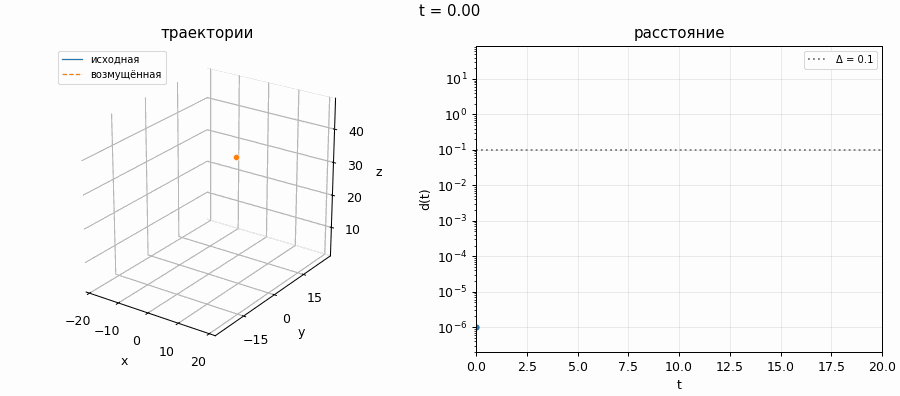

In [13]:
from pathlib import Path
from tempfile import TemporaryDirectory
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.ticker import MaxNLocator
from IPython.display import Image, display


def animate_pair(t, states, distances, threshold, fps=20):  # две траектории и синхронный график расстояния
    fig = plt.figure(figsize=(10, 4.4), dpi=90, constrained_layout=True)
    ax_space = fig.add_subplot(1, 2, 1, projection='3d')
    ax_distance = fig.add_subplot(1, 2, 2)
    flat = states.reshape(-1, 3)
    low, high = flat.min(axis=0), flat.max(axis=0)
    padding = 0.08 * (high - low)
    ax_space.set(xlim=(low[0] - padding[0], high[0] + padding[0]),
                 ylim=(low[1] - padding[1], high[1] + padding[1]),
                 zlim=(low[2] - padding[2], high[2] + padding[2]),
                 xlabel='x', ylabel='y', zlabel='z', title='траектории')
    ax_space.set_box_aspect(high - low)
    ax_space.view_init(elev=24, azim=-55)
    for axis in [ax_space.xaxis, ax_space.yaxis, ax_space.zaxis]:
        axis.set_major_locator(MaxNLocator(5))
    lines, dots = [], []
    for color, style, label in [('tab:blue', '-', 'исходная'), ('tab:orange', '--', 'возмущённая')]:
        line, = ax_space.plot([], [], [], color=color, linestyle=style, linewidth=1, label=label)
        dot, = ax_space.plot([], [], [], 'o', color=color, markersize=5,
                             markeredgecolor='white', markeredgewidth=0.5)
        lines.append(line)
        dots.append(dot)
    ax_space.legend(loc='upper left', fontsize=8)

    ax_distance.set_yscale('log')
    ax_distance.set(xlim=(0, t[-1]), ylim=(distances.min() / 2, distances.max() * 2),
                    xlabel='t', ylabel='d(t)', title='расстояние')
    ax_distance.axhline(threshold, color='gray', linestyle=':', label='Δ = 0.1')
    distance_line, = ax_distance.plot([], [], color='tab:blue')
    distance_dot, = ax_distance.plot([], [], 'o', color='tab:blue', markersize=4)
    cursor = ax_distance.axvline(0, color='gray', linestyle='--', linewidth=0.8)
    ax_distance.grid(alpha=0.25)
    ax_distance.legend(loc='upper right', fontsize=8)
    title = fig.suptitle('t = 0.00')
    stride = round(1 / (fps * (t[1] - t[0])))
    frames = np.arange(0, len(t), stride)

    def update(i):  # положения обеих точек, их следы и расстояние при одном времени
        for j, (line, dot) in enumerate(zip(lines, dots)):
            line.set_data_3d(states[:i + 1, j].T)
            dot.set_data_3d(states[i:i + 1, j].T)
        distance_line.set_data(t[:i + 1], distances[:i + 1])
        distance_dot.set_data([t[i]], [distances[i]])
        cursor.set_xdata([t[i], t[i]])
        title.set_text(f't = {t[i]:.2f}')
        return lines + dots + [distance_line, distance_dot, cursor, title]

    animation = FuncAnimation(fig, update, frames=frames, interval=1000 / fps, blit=False)
    plt.close(fig)
    return animation


animation_mask = t_pair <= 20
print(f'Изменение положения при дополнительном уточнении на участке анимации: '
      f'{fine_difference[animation_mask].max():.3e}')
lorenz_animation = animate_pair(t_pair[animation_mask], pair_fine[animation_mask],
                                distance_fine[animation_mask], threshold)
with TemporaryDirectory() as directory:
    gif_path = Path(directory) / 'lorenz.gif'
    lorenz_animation.save(gif_path, writer=PillowWriter(fps=20))
    display(Image(filename=str(gif_path)))


## вывод

При $\rho=10$ получено $\lambda_{\max}\approx-0.596$: возмущения затухают, траектория приходит к устойчивому равновесию. Оценка согласуется с линеаризацией системы в этой точке.

При $\rho=28$ основной расчёт даёт $\lambda_{\max}\approx0.914$. При изменении начального расстояния, интервала перенормировки и точности интегрирования оценки за $T=500$ лежат примерно между 0.895 и 0.910. Положительный знак и масштаб показателя сохраняются.

Для $\delta_0=10^{-6}$ и $\Delta=0.1$ теоретический горизонт равен примерно 12.60. У шести пар первое достижение порога происходит между 8.82 и 11.59, медиана — 10.47. Различие связано с конечным временем наблюдения и неодинаковой скоростью растяжения в разных частях аттрактора.

Уменьшение начальной ошибки в десять раз добавляет примерно **2.52 единицы времени**. Это логарифмический рост горизонта, а не увеличение в десять раз.
